# 04. Two-head LSTM

One LSTM reads a ticker's last 30 days and predicts two things for the next trading day: the **log return** (turned into a
close price with `Close * exp(return)`) and the **volatility** `log(High / Low)`. Both heads share the same encoder and the
same all-ticker training data, so any ticker can be forecast by feeding in its own window.

The bars from `03_baselines.ipynb`:
- **Return:** beat predicting zero, with a day-clustered 95% interval above 0. No baseline did.
- **Volatility:** beat the 5-day mean range (and ideally the gradient boosting model, the best baseline).

Several variants are trained and one is chosen on **validation** loss. The test period is scored once for reporting.

In [1]:
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
from IPython.display import Markdown, display
from sklearn.ensemble import HistGradientBoostingRegressor

from formative_1 import stock_data as sd
from formative_1.lstm_model import DEVICE, TwoHeadLSTM, fit, predict
from formative_1.scoring import day_clustered_gain

warnings.filterwarnings("ignore", category=RuntimeWarning)
SEED = 42
print("device:", DEVICE)

device: cpu


## Data, split and scaling

Same windows, same chronological split and the same training-only scaling as notebook 02. Both targets are divided by
their training standard deviation so the two heads have comparable loss.

In [2]:
clean = pl.read_parquet("../data/processed/clean.parquet")
X, y, day, ticker, close, y_vol = sd.make_windows(
    sd.add_features(clean), extras=("Ticker", "Close", "target_vol")
)
train, val, test = sd.split_masks(day)

mean, std = X[train].mean(axis=(0, 1)), X[train].std(axis=(0, 1))
y_std, vol_std = float(y[train].std()), float(y_vol[train].std())
Xs = torch.from_numpy((X - mean) / std)
Y = torch.from_numpy(np.column_stack([y / y_std, y_vol / vol_std]).astype(np.float32))

tickers = np.unique(ticker)
ticker_id = torch.from_numpy(np.searchsorted(tickers, ticker))
train_tickers = np.unique(ticker[train])
print(f"{len(y):,} samples; train {train.sum():,} / val {val.sum():,} / test {test.sum():,}; {len(tickers)} tickers ({len(train_tickers)} with training data)")

299,770 samples; train 204,210 / val 43,031 / test 52,529; 61 tickers (53 with training data)


## Reference forecasts

The comparators from `03`, recomputed here so every model is scored on identical samples: predict zero return, the
5-day mean range for volatility, and the gradient boosting volatility model with the settings chosen in `03`.

In [3]:
T, names = sd.window_summary(X)
col = {n: i for i, n in enumerate(names)}
ref_vol = T[:, col["hl_mean_5"]]
gb = HistGradientBoostingRegressor(
    max_depth=6, max_iter=200, learning_rate=0.05, min_samples_leaf=200, l2_regularization=1.0, random_state=SEED
).fit(T[train], y_vol[train] / vol_std)
gb_vol = gb.predict(T) * vol_std
zero_ret = np.zeros_like(y)
display(Markdown(f"Gradient boosting volatility MSE: val {np.mean((gb_vol[val] - y_vol[val]) ** 2):.3e}, test {np.mean((gb_vol[test] - y_vol[test]) ** 2):.3e}."))

Gradient boosting volatility MSE: val 2.940e-04, test 1.907e-04.

## Scoring

For each model and split: return MSE, R² vs zero, direction accuracy and the day-clustered gain over zero; volatility MSE,
R², R² vs the 5-day mean reference, and the day-clustered gain over both the reference and gradient boosting.
`val_loss` is the mean scaled MSE of both heads, used to choose the final variant.

In [4]:
def evaluate(name, scaled_pred, rows):
    pr, pv = scaled_pred[:, 0] * y_std, scaled_pred[:, 1] * vol_std
    for split, mask in [("val", val), ("test", test)]:
        mse_r = float(np.mean((y[mask] - pr[mask]) ** 2))
        mse_v = float(np.mean((y_vol[mask] - pv[mask]) ** 2))
        ref_mse = float(np.mean((y_vol[mask] - ref_vol[mask]) ** 2))
        g_r, ci_r = day_clustered_gain(y, pr, zero_ret, day, mask)
        g_ref, ci_ref = day_clustered_gain(y_vol, pv, ref_vol, day, mask)
        g_gb, ci_gb = day_clustered_gain(y_vol, pv, gb_vol, day, mask)
        rows.append(
            {
                "model": name, "split": split,
                "val_loss": float(np.mean((scaled_pred[mask] - Y.numpy()[mask]) ** 2)),
                "ret_mse": mse_r,
                "ret_r2_vs_zero": 1 - mse_r / float(np.mean(y[mask] ** 2)),
                "ret_direction": float(np.mean(np.sign(y[mask]) == np.sign(pr[mask]))),
                "ret_gain": g_r, "ret_ci95": ci_r,
                "vol_mse": mse_v,
                "vol_r2": 1 - mse_v / float(np.var(y_vol[mask])),
                "vol_r2_vs_ref": 1 - mse_v / ref_mse,
                "vol_gain_vs_ref": g_ref, "vol_ci_ref": ci_ref,
                "vol_gain_vs_gb": g_gb, "vol_ci_gb": ci_gb,
            }
        )


def train_variant(name, seed=SEED, hidden=64, use_ticker=False, verbose=False):
    torch.manual_seed(seed)
    np.random.seed(seed)
    model = TwoHeadLSTM(len(sd.FEATURES), hidden=hidden, n_tickers=len(tickers) if use_ticker else 0)
    t0 = time.time()
    tid = ticker_id if use_ticker else None
    model, history = fit(model, Xs, Y, train, val, ticker=tid, seed=seed, verbose=verbose)
    pred = predict(model, Xs, tid)
    print(f"{name}: {len(history)} epochs, best val loss {min(h['val'] for h in history):.4f}, {time.time() - t0:.0f}s")
    return model, history, pred

## Base model

A 2-layer LSTM with 64 hidden units and 0.2 dropout between layers. Adam at 1e-3, gradient clipping, and early stopping
with patience 3 on the validation loss. The weights from the best epoch are kept.

In [5]:
base_model, base_hist, base_pred = train_variant("LSTM 64", verbose=True)

epoch  1  train 0.7575  val 0.9262  (return 1.1964, vol 0.6560)


epoch  2  train 0.7139  val 0.9139  (return 1.1954, vol 0.6324)


epoch  3  train 0.7122  val 0.9149  (return 1.1906, vol 0.6391)


epoch  4  train 0.7114  val 0.9112  (return 1.1941, vol 0.6284)


epoch  5  train 0.7096  val 0.9167  (return 1.1921, vol 0.6413)


...

epoch  8  train 0.7071  val 0.9023  (return 1.1774, vol 0.6273)


epoch  9  train 0.7037  val 0.9094  (return 1.1807, vol 0.6381)


epoch 10  train 0.7010  val 0.9098  (return 1.1863, vol 0.6334)


epoch 11  train 0.6973  val 0.9082  (return 1.1809, vol 0.6355)


LSTM 64: 11 epochs, best val loss 0.9023, 472s


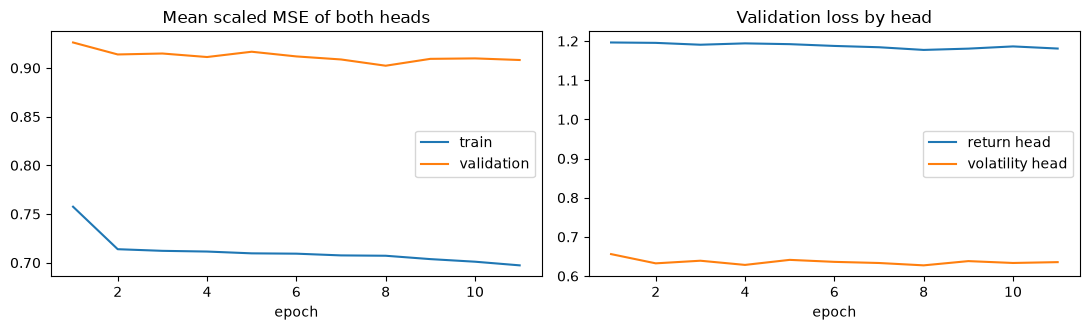

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ep = [h["epoch"] for h in base_hist]
axes[0].plot(ep, [h["train"] for h in base_hist], label="train")
axes[0].plot(ep, [h["val"] for h in base_hist], label="validation")
axes[0].set(title="Mean scaled MSE of both heads", xlabel="epoch")
axes[0].legend()
axes[1].plot(ep, [h["val_return"] for h in base_hist], label="return head")
axes[1].plot(ep, [h["val_vol"] for h in base_hist], label="volatility head")
axes[1].set(title="Validation loss by head", xlabel="epoch")
axes[1].legend()
fig.tight_layout()
plt.show()

## Variants

Everything is trained the same way, changing one thing at a time:
- **LSTM 128**: twice the hidden units.
- **LSTM 64 + ticker embedding**: an 8-dimensional learned vector per ticker, so the model can treat tickers differently. Tickers with no training windows (those listed after 2018) keep an untrained embedding.
- **LSTM 64 ensemble**: the average of three seeds (42, 43, 44), which reduces the variance from random initialisation and batch order.

In [7]:
candidates = {"LSTM 64": ([base_model], base_pred, {"hidden": 64, "use_ticker": False})}

m, _, p = train_variant("LSTM 128", hidden=128)
candidates["LSTM 128"] = ([m], p, {"hidden": 128, "use_ticker": False})

m, _, p = train_variant("LSTM 64 + ticker embedding", use_ticker=True)
candidates["LSTM 64 + ticker embedding"] = ([m], p, {"hidden": 64, "use_ticker": True})

members, preds_ens = [base_model], [base_pred]
for s in (43, 44):
    m, _, p = train_variant(f"LSTM 64 seed {s}", seed=s)
    members.append(m)
    preds_ens.append(p)
candidates["LSTM 64 ensemble"] = (members, np.mean(preds_ens, axis=0), {"hidden": 64, "use_ticker": False})

LSTM 128: 11 epochs, best val loss 0.8976, 1209s


LSTM 64 + ticker embedding: 11 epochs, best val loss 0.9062, 430s


LSTM 64 seed 43: 14 epochs, best val loss 0.8993, 549s


LSTM 64 seed 44: 8 epochs, best val loss 0.9102, 342s


## Comparison

The first two rows are the baselines: **zero return with gradient boosting volatility** (the best of `03`), and **zero return
with the 5-day mean range**.

In [8]:
rows = []
evaluate("baseline: zero return + gradient boosting", np.column_stack([zero_ret / y_std, gb_vol / vol_std]), rows)
evaluate("baseline: zero return + 5-day mean range", np.column_stack([zero_ret / y_std, ref_vol / vol_std]), rows)
for name, (_, pred, _) in candidates.items():
    evaluate(name, pred, rows)
results = pl.DataFrame(rows)

r4 = lambda *c: pl.col(*c).round(4)
display(Markdown("**Return head, test period.** R² vs zero, direction accuracy, and the gain over predicting zero (MSE units, 95% CI by day)."))
display(
    results.filter(pl.col("split") == "test")
    .select("model", r4("ret_r2_vs_zero"), r4("ret_direction"), pl.col("ret_gain").round(9), pl.col("ret_ci95").round(9))
)
display(Markdown("**Volatility head, test period.** R², R² vs the 5-day mean range, and the gain over the reference and over gradient boosting."))
display(
    results.filter(pl.col("split") == "test")
    .select("model", r4("vol_r2"), r4("vol_r2_vs_ref"), pl.col("vol_gain_vs_ref").round(9), pl.col("vol_ci_ref").round(9), pl.col("vol_gain_vs_gb").round(9), pl.col("vol_ci_gb").round(9))
)

**Return head, test period.** R² vs zero, direction accuracy, and the gain over predicting zero (MSE units, 95% CI by day).

model,ret_r2_vs_zero,ret_direction,ret_gain,ret_ci95
str,f64,f64,f64,f64
"""baseline: zero return + gradie…",0.0,0.0076,-0.0,0.0
"""baseline: zero return + 5-day …",0.0,0.0076,0.0,0.0
"""LSTM 64""",0.0034,0.5082,0.000003,0.000008
"""LSTM 128""",-0.0033,0.5077,-0.000003,0.000007
"""LSTM 64 + ticker embedding""",0.0053,0.5091,0.000004,0.000009
"""LSTM 64 ensemble""",0.0019,0.5089,0.000001,0.000004


**Volatility head, test period.** R², R² vs the 5-day mean range, and the gain over the reference and over gradient boosting.

model,vol_r2,vol_r2_vs_ref,vol_gain_vs_ref,vol_ci_ref,vol_gain_vs_gb,vol_ci_gb
str,f64,f64,f64,f64,f64,f64
"""baseline: zero return + gradie…",0.5737,0.1368,0.00003,0.000011,0.0,0.0
"""baseline: zero return + 5-day …",0.5061,0.0,0.0,0.0,-0.00003,0.000011
"""LSTM 64""",0.582,0.1537,0.000034,0.000009,0.000004,0.000004
"""LSTM 128""",0.5728,0.135,0.00003,0.000009,-4.1000e-7,0.000004
"""LSTM 64 + ticker embedding""",0.5796,0.1488,0.000033,0.000009,0.000003,0.000004
"""LSTM 64 ensemble""",0.5816,0.1528,0.000034,0.00001,0.000004,0.000003


In [9]:
display(Markdown("**Validation period** (used to choose the variant)."))
results.filter(pl.col("split") == "val").select(
    "model", pl.col("val_loss").round(5), r4("ret_r2_vs_zero"), r4("vol_r2"), r4("vol_r2_vs_ref")
)

**Validation period** (used to choose the variant).

model,val_loss,ret_r2_vs_zero,vol_r2,vol_r2_vs_ref
str,f64,f64,f64,f64
"""baseline: zero return + gradie…",0.92022,0.0,0.501,0.1369
"""baseline: zero return + 5-day …",0.97137,0.0,0.4218,-0.0
"""LSTM 64""",0.90232,0.0154,0.5145,0.1602
"""LSTM 128""",0.8976,0.0281,0.51,0.1525
"""LSTM 64 + ticker embedding""",0.90623,0.0127,0.5109,0.1541
"""LSTM 64 ensemble""",0.9009,0.0144,0.5176,0.1657


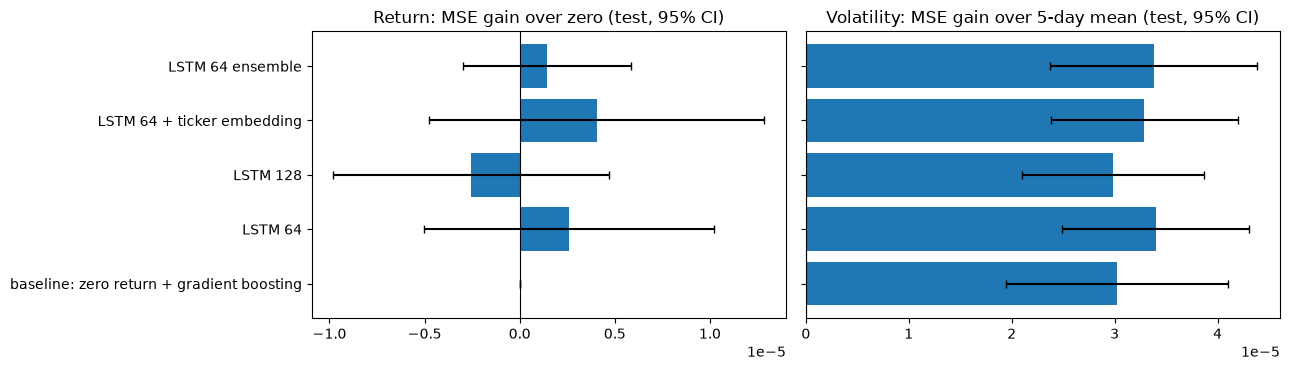

In [10]:
test_r = results.filter((pl.col("split") == "test") & ~pl.col("model").str.starts_with("baseline: zero return + 5"))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].barh(test_r["model"], test_r["ret_gain"], xerr=test_r["ret_ci95"], capsize=3)
axes[0].axvline(0, c="black", lw=0.8)
axes[0].set(title="Return: MSE gain over zero (test, 95% CI)")
axes[1].barh(test_r["model"], test_r["vol_gain_vs_ref"], xerr=test_r["vol_ci_ref"], capsize=3)
axes[1].axvline(0, c="black", lw=0.8)
axes[1].set(title="Volatility: MSE gain over 5-day mean (test, 95% CI)")
axes[1].set_yticklabels([])
fig.tight_layout()
plt.show()

## Choosing the final model

By lowest validation loss among the LSTM variants, which is the fair rule because the test period was not used for any
choice.

In [11]:
lstm_val = results.filter((pl.col("split") == "val") & pl.col("model").str.starts_with("LSTM")).sort("val_loss")
chosen = lstm_val["model"][0]
chosen_models, chosen_pred, chosen_cfg = candidates[chosen]
display(Markdown(f"Chosen on validation loss: **{chosen}** (validation loss {lstm_val['val_loss'][0]:.5f})."))
lstm_val.select("model", pl.col("val_loss").round(5))

Chosen on validation loss: **LSTM 128** (validation loss 0.89760).

model,val_loss
str,f64
"""LSTM 128""",0.8976
"""LSTM 64 ensemble""",0.9009
"""LSTM 64""",0.90232
"""LSTM 64 + ticker embedding""",0.90623


## Per-ticker view

The chosen model on each ticker's test samples. Return is scored against zero and volatility against the 5-day mean
reference and against gradient boosting.

In [12]:
pr, pv = chosen_pred[:, 0] * y_std, chosen_pred[:, 1] * vol_std
per_ticker = (
    pl.DataFrame(
        {"ticker": ticker[test], "y": y[test], "pr": pr[test], "v": y_vol[test], "pv": pv[test], "ref": ref_vol[test], "gb": gb_vol[test]}
    )
    .group_by("ticker")
    .agg(
        n=pl.len(),
        ret_mse=((pl.col("y") - pl.col("pr")) ** 2).mean(),
        ret_zero=(pl.col("y") ** 2).mean(),
        vol_mse=((pl.col("v") - pl.col("pv")) ** 2).mean(),
        vol_ref=((pl.col("v") - pl.col("ref")) ** 2).mean(),
        vol_gb=((pl.col("v") - pl.col("gb")) ** 2).mean(),
        direction=(pl.col("y").sign() == pl.col("pr").sign()).mean(),
    )
    .with_columns(
        ret_r2_vs_zero=1 - pl.col("ret_mse") / pl.col("ret_zero"),
        vol_r2_vs_ref=1 - pl.col("vol_mse") / pl.col("vol_ref"),
        vol_r2_vs_gb=1 - pl.col("vol_mse") / pl.col("vol_gb"),
    )
    .sort("vol_r2_vs_ref", descending=True)
)
k = per_ticker.height
display(Markdown(
    f"**{chosen}** on the test period: beats zero return on **{per_ticker.filter(pl.col('ret_r2_vs_zero') > 0).height} of {k}** tickers; "
    f"beats the 5-day mean range on **{per_ticker.filter(pl.col('vol_r2_vs_ref') > 0).height} of {k}**; "
    f"beats gradient boosting on **{per_ticker.filter(pl.col('vol_r2_vs_gb') > 0).height} of {k}**."
))
per_ticker.select("ticker", "n", r4("ret_r2_vs_zero"), r4("direction"), r4("vol_r2_vs_ref"), r4("vol_r2_vs_gb"))

**LSTM 128** on the test period: beats zero return on **16 of 61** tickers; beats the 5-day mean range on **59 of 61**; beats gradient boosting on **18 of 61**.

ticker,n,ret_r2_vs_zero,direction,vol_r2_vs_ref,vol_r2_vs_gb
str,u32,f32,f64,f64,f64
"""AEO""",872,0.0213,0.4748,0.1921,0.0147
"""AAPL""",872,-0.008,0.5333,0.19,-0.0301
"""FL""",872,0.0142,0.5252,0.182,0.0051
"""DAL""",872,-0.0011,0.5069,0.1814,-0.021
"""FDX""",872,-0.0066,0.5252,0.1772,-0.0278
…,…,…,…,…,…
"""MCD""",872,-0.0339,0.5229,0.029,-0.0424
"""JNJ""",872,-0.0162,0.5103,0.0177,-0.0914
"""BAMXF""",579,0.0098,0.4352,0.0165,-0.1259


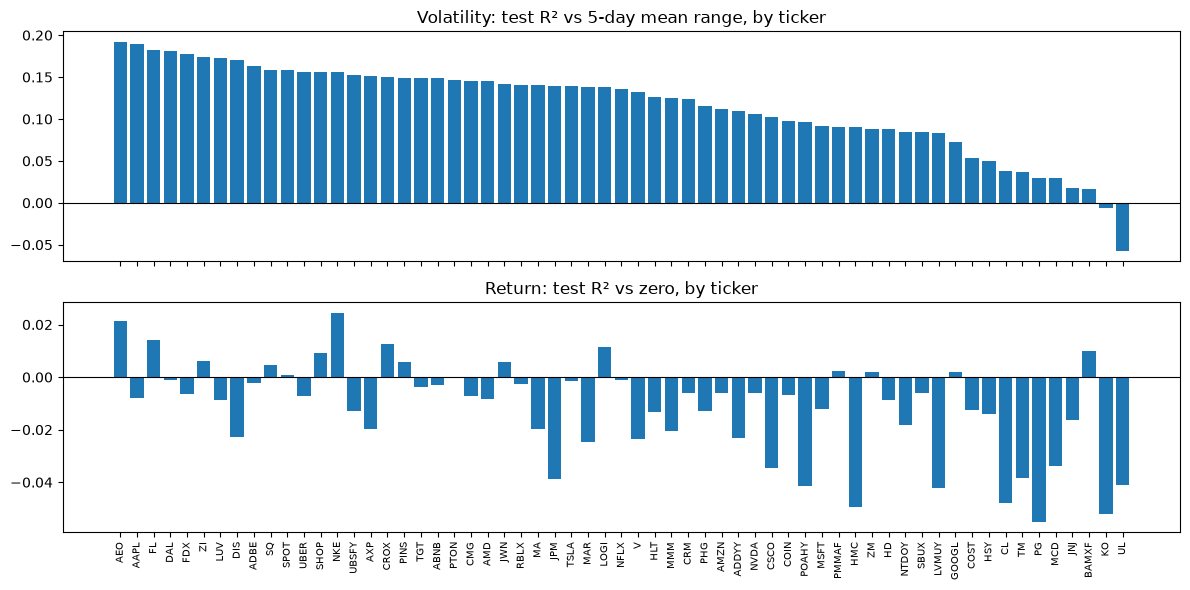

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].bar(per_ticker["ticker"], per_ticker["vol_r2_vs_ref"])
axes[0].axhline(0, c="black", lw=0.8)
axes[0].set(title="Volatility: test R² vs 5-day mean range, by ticker")
axes[1].bar(per_ticker["ticker"], per_ticker["ret_r2_vs_zero"])
axes[1].axhline(0, c="black", lw=0.8)
axes[1].set(title="Return: test R² vs zero, by ticker")
axes[1].tick_params(axis="x", rotation=90, labelsize=7)
fig.tight_layout()
plt.show()

## Price forecast

The return head converted to prices, `Close * exp(return)`, scored against "tomorrow's close = today's close".

In [14]:
actual_close = close * np.exp(y)
price = pl.DataFrame(
    {
        "model": ["tomorrow = today", chosen],
        "val_MAPE_%": [
            float(np.mean(np.abs(close[val] - actual_close[val]) / actual_close[val]) * 100),
            float(np.mean(np.abs(close[val] * np.exp(pr[val]) - actual_close[val]) / actual_close[val]) * 100),
        ],
        "test_MAPE_%": [
            float(np.mean(np.abs(close[test] - actual_close[test]) / actual_close[test]) * 100),
            float(np.mean(np.abs(close[test] * np.exp(pr[test]) - actual_close[test]) / actual_close[test]) * 100),
        ],
    }
)
price.with_columns(pl.col("val_MAPE_%", "test_MAPE_%").round(4))

model,val_MAPE_%,test_MAPE_%
str,f64,f64
"""tomorrow = today""",1.6709,1.7845
"""LSTM 128""",1.6608,1.791


## Summary

In [15]:
t = results.filter((pl.col("split") == "test") & (pl.col("model") == chosen)).row(0, named=True)
ret_sig = t["ret_gain"] - t["ret_ci95"] > 0
vol_sig_ref = t["vol_gain_vs_ref"] - t["vol_ci_ref"] > 0
vol_sig_gb = t["vol_gain_vs_gb"] - t["vol_ci_gb"] > 0
vol_worse_gb = t["vol_gain_vs_gb"] + t["vol_ci_gb"] < 0
display(Markdown(f"""
**{chosen}, test period (2022 onward)**

- **Return / price:** R² vs zero {t['ret_r2_vs_zero']:+.4f}, direction accuracy {t['ret_direction']:.3f}. The improvement over zero is
  {'distinguishable from 0' if ret_sig else 'not distinguishable from 0'}.
- **Volatility:** R² {t['vol_r2']:.3f}, R² vs the 5-day mean range {t['vol_r2_vs_ref']:+.3f}
  ({'significantly better' if vol_sig_ref else 'not significantly better'} than the reference).
- **Against gradient boosting:** {'significantly better' if vol_sig_gb else ('significantly worse' if vol_worse_gb else 'not distinguishable from')} (gain {t['vol_gain_vs_gb']:.2e} ± {t['vol_ci_gb']:.2e}).
"""))


**LSTM 128, test period (2022 onward)**

- **Return / price:** R² vs zero -0.0033, direction accuracy 0.508. The improvement over zero is
  not distinguishable from 0.
- **Volatility:** R² 0.573, R² vs the 5-day mean range +0.135
  (significantly better than the reference).
- **Against gradient boosting:** not distinguishable from (gain -4.10e-07 ± 4.15e-06).


## Save the model

The chosen variant's weights and everything needed to reuse them for inference: the scaling statistics, feature order, window length,
target scales and the ticker list.

In [16]:
OUT = Path("../models")
OUT.mkdir(exist_ok=True)
torch.save(
    {
        "name": chosen,
        "states": [m.state_dict() for m in chosen_models],
        "config": {**chosen_cfg, "n_features": len(sd.FEATURES), "n_tickers": len(tickers) if chosen_cfg["use_ticker"] else 0},
        "mean": mean.tolist(),
        "std": std.tolist(),
        "y_std": y_std,
        "vol_std": vol_std,
        "features": sd.FEATURES,
        "window": sd.WINDOW,
        "tickers": tickers.tolist(),
    },
    OUT / "lstm_two_head.pt",
)
metadata = {
    "model": chosen,
    "targets": {"return": "next-day log return; price = Close * exp(return)", "volatility": "next-day log(High/Low)"},
    "split": {"val_start": str(sd.VAL_START), "test_start": str(sd.TEST_START)},
    "test_metrics": {k: v for k, v in t.items() if k not in ("model", "split")},
}
(OUT / "lstm_two_head.json").write_text(json.dumps(metadata, indent=2))
results.write_csv("../data/processed/lstm_results.csv")
print("saved", OUT / "lstm_two_head.pt")

saved ../models/lstm_two_head.pt
